In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os

In [4]:
dengue_df = pd.read_csv('All Dengue Data.csv')
weather_df = pd.read_csv('cleaned_weather.csv')
population_df = pd.read_csv('population_data.csv')
hospitalBed_df = pd.read_csv('Hospital_Bed_Counts_final.csv')

In [5]:
dengue_df.head()

,year,week,start.date,end.date,district,cases
0,2020,1,12/28/2019,1/3/2020,Colombo,535.0
1,2020,1,12/28/2019,1/3/2020,Gampaha,362.0
2,2020,1,12/28/2019,1/3/2020,Kalutara,168.0
3,2020,1,12/28/2019,1/3/2020,Kandy,199.0
4,2020,1,12/28/2019,1/3/2020,Matale,101.0


In [6]:
dengue_df.isnull().sum()

year           0
week           0
start.date     0
end.date       0
district       0
cases         77
dtype: int64

In [7]:
dengue_df.fillna(0, inplace=True)

In [8]:
weather_df.head()

,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,wind_speed_10m_max,district
0,2019-12-01,29.6,23.8,25.9,6.9,6.9,10.7,Ampara
1,2019-12-02,27.8,23.9,25.1,15.4,15.4,10.7,Ampara
2,2019-12-03,27.5,24.4,25.4,16.7,16.7,14.7,Ampara
3,2019-12-04,27.8,24.3,25.4,27.4,27.4,14.6,Ampara
4,2019-12-05,28.0,23.8,25.2,19.1,19.1,15.6,Ampara


In [9]:
weather_df.drop(columns=['temperature_2m_min', 'temperature_2m_max', 'precipitation_sum', 'wind_speed_10m_max'], axis=1, inplace=True)

In [10]:
weather_df

,time,temperature_2m_mean,rain_sum,district
0,2019-12-01,25.9,6.9,Ampara
1,2019-12-02,25.1,15.4,Ampara
2,2019-12-03,25.4,16.7,Ampara
3,2019-12-04,25.4,27.4,Ampara
4,2019-12-05,25.2,19.1,Ampara
...,...,...,...,...
56023,2026-07-28,30.2,0.3,Vavuniya
56024,2026-07-29,30.4,0.7,Vavuniya
56025,2026-07-30,30.4,1.0,Vavuniya
56026,2026-07-31,30.5,0.4,Vavuniya


In [11]:
weather_df.rename(columns={'temperature_2m_mean': 'mean temperature', 'rain_sum': 'rainfall', 'time': 'date'}, inplace=True)
weather_df['date'] = pd.to_datetime(weather_df['date'])
weather_df = weather_df[weather_df['date'] >= '2019-12-28'].copy()
weather_df['week'] = weather_df['date'].dt.to_period('W')
weather_df

,date,mean temperature,rainfall,district,week
27,2019-12-28,25.5,1.9,Ampara,2019-12-23/2019-12-29
28,2019-12-29,25.0,0.0,Ampara,2019-12-23/2019-12-29
29,2019-12-30,25.7,0.0,Ampara,2019-12-30/2020-01-05
30,2019-12-31,25.8,1.6,Ampara,2019-12-30/2020-01-05
31,2020-01-01,26.3,3.4,Ampara,2019-12-30/2020-01-05
...,...,...,...,...,...
56023,2026-07-28,30.2,0.3,Vavuniya,2026-07-27/2026-08-02
56024,2026-07-29,30.4,0.7,Vavuniya,2026-07-27/2026-08-02
56025,2026-07-30,30.4,1.0,Vavuniya,2026-07-27/2026-08-02
56026,2026-07-31,30.5,0.4,Vavuniya,2026-07-27/2026-08-02


In [12]:
anchor_date = pd.to_datetime('2019-12-28')

weather_df['days_diff'] = (weather_df['date'] - anchor_date).dt.days
weather_df['custom_week_index'] = weather_df['days_diff'] // 7

weather_df['week_start'] = anchor_date + pd.to_timedelta(weather_df['custom_week_index'] * 7, unit='D')
weather_df['week_end'] = weather_df['week_start'] + pd.Timedelta(days=6)

weather_df['year'] = weather_df['week_end'].dt.year

min_week_per_year = weather_df.groupby('year')['custom_week_index'].transform('min')
weather_df['yearly_week_num'] = (weather_df['custom_week_index'] - min_week_per_year) + 1

weekly_weather = weather_df.groupby([
    'district', 'year', 'yearly_week_num', 'week_start', 'week_end'
]).agg(
    mean_temperature=('mean temperature', 'mean'),
    weekly_rainfall=('rainfall', 'sum')
).reset_index()

weekly_weather['week_start'] = weekly_weather['week_start'].dt.strftime('%Y-%m-%d')
weekly_weather['week_end'] = weekly_weather['week_end'].dt.strftime('%Y-%m-%d')
weekly_weather['mean_temperature'] = weekly_weather['mean_temperature'].round(2)

weekly_weather = weekly_weather[['district', 'year', 'yearly_week_num', 'week_start', 'week_end', 'mean_temperature', 'weekly_rainfall']]
weekly_weather.head(20)

,district,year,yearly_week_num,week_start,week_end,mean_temperature,weekly_rainfall
0,Ampara,2020,1,2019-12-28,2020-01-03,25.87,15.2
1,Ampara,2020,2,2020-01-04,2020-01-10,25.77,13.0
2,Ampara,2020,3,2020-01-11,2020-01-17,24.86,13.3
3,Ampara,2020,4,2020-01-18,2020-01-24,26.14,31.5
4,Ampara,2020,5,2020-01-25,2020-01-31,25.17,0.8
5,Ampara,2020,6,2020-02-01,2020-02-07,25.73,5.2
6,Ampara,2020,7,2020-02-08,2020-02-14,25.81,18.1
7,Ampara,2020,8,2020-02-15,2020-02-21,25.76,16.6
8,Ampara,2020,9,2020-02-22,2020-02-28,26.33,13.5
9,Ampara,2020,10,2020-02-29,2020-03-06,26.40,1.8


In [13]:
population_df.head()

,district,total,male,female
0,Sri Lanka,21756000,10500000,11256000
1,Colombo,2371000,1153000,1218000
2,Gampaha,2431000,1173000,1258000
3,Kalutara,1302000,629000,673000
4,Kandy,1460000,696000,764000


In [14]:
population_df.rename(columns={'district': 'District', 'total': 'Population Count'}, inplace=True)

population_df = population_df.drop(0)
population_df

,District,Population Count,male,female
1,Colombo,2371000,1153000,1218000
2,Gampaha,2431000,1173000,1258000
3,Kalutara,1302000,629000,673000
4,Kandy,1460000,696000,764000
5,Matale,526000,255000,271000
6,Nuwara-eliya,726000,347000,379000
7,Galle,1096000,527000,569000
8,Matara,836000,401000,435000
9,Hambantota,671000,329000,342000
10,Jaffna,595000,282000,313000


In [15]:
population_df.isnull().sum()

District            0
Population Count    0
male                0
female              0
dtype: int64

In [16]:
hospitalBed_df.head()

,District,Hospital Name,Total Hospital Beds
0,Colombo,National Hospital of Sri Lanka,3413.0
1,Kandy,National Hospital - Kandy,2808.0
2,Galle,National Hospital - Galle,2107.0
3,Anuradhapura,Teaching Hospital- Anuradhapura,2037.0
4,Batticaloa,Teaching Hospital- Batticaloa,1257.0


In [17]:
hospitalBed_df.isnull().sum()

District               0
Hospital Name          0
Total Hospital Beds    8
dtype: int64

In [18]:
hospitalBed_df.fillna(0, inplace=True)

#Assuming that 40% of the total beds are allocated for dengue patients, we can calculate the number of beds for dengue by multiplying the total beds by 0.4.
hospitalBed_df['beds for dengue'] = (hospitalBed_df['Total Hospital Beds'] * 0.3).astype(int)

hospitalBed_df 

,District,Hospital Name,Total Hospital Beds,beds for dengue
0,Colombo,National Hospital of Sri Lanka,3413.0,1023
1,Kandy,National Hospital - Kandy,2808.0,842
2,Galle,National Hospital - Galle,2107.0,632
3,Anuradhapura,Teaching Hospital- Anuradhapura,2037.0,611
4,Batticaloa,Teaching Hospital- Batticaloa,1257.0,377
...,...,...,...,...
608,Vavuniya,DHC Omanthai,0.0,0
609,Vavuniya,DHC Pavatkulam,0.0,0
610,Vavuniya,DHC Puliyankulam,6.0,1
611,Vavuniya,Sithamparapuram,11.0,3


In [19]:
bedsByDistricts = hospitalBed_df.groupby('District').agg({'Total Hospital Beds': 'sum', 'beds for dengue': 'sum'}).reset_index().sort_values(by='beds for dengue', ascending=False)

bedsByDistricts['Total Hospital Beds'] = bedsByDistricts['Total Hospital Beds'].astype(int)
bedsByDistricts

,District,Total Hospital Beds,beds for dengue
4,Colombo,7682,2299
11,Kandy,7053,2094
14,Kurunegala,6656,1977
6,Gampaha,5301,1582
24,Ratnapura,4703,1394
1,Anuradhapura,4250,1259
5,Galle,4219,1256
10,Kalutara,4201,1248
2,Badulla,4202,1237
8,Jaffna,3553,1052


## Data Visualization


[]

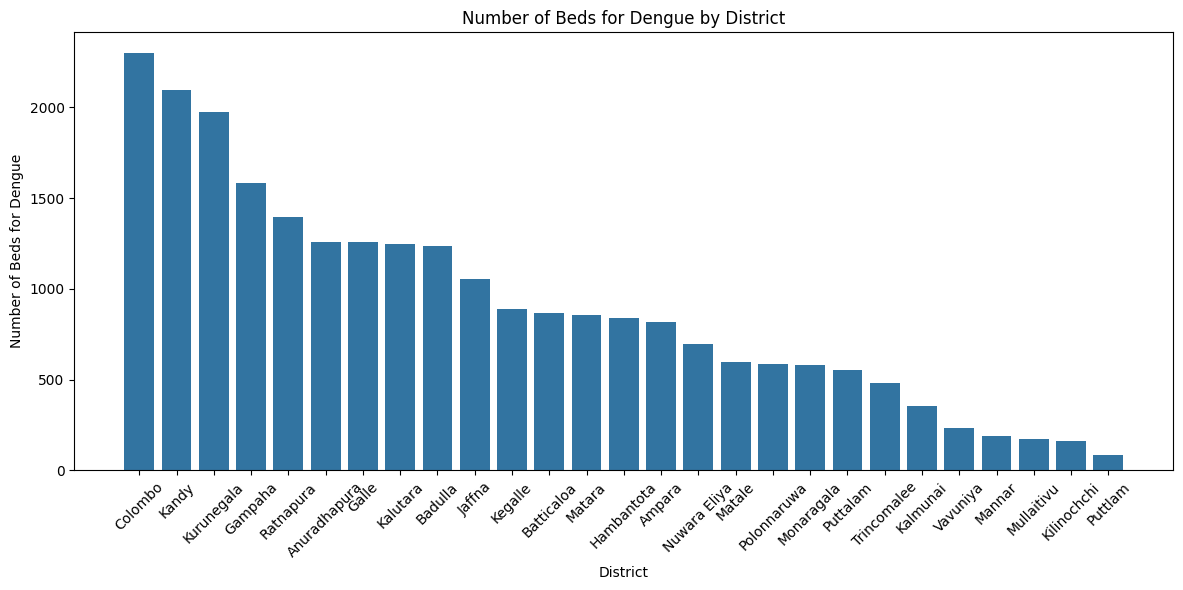

In [20]:
plt.figure(figsize=(12, 6))
sns.barplot(x='District', y='beds for dengue', data=bedsByDistricts)
plt.title('Number of Beds for Dengue by District')
plt.xlabel('District')
plt.ylabel('Number of Beds for Dengue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.plot()

## 1. Dengue Cases Visualizations

C:\Users\theek\AppData\Local\Temp\ipykernel_41024\966323617.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='year', y='cases', data=annual_cases, palette='Reds_r')


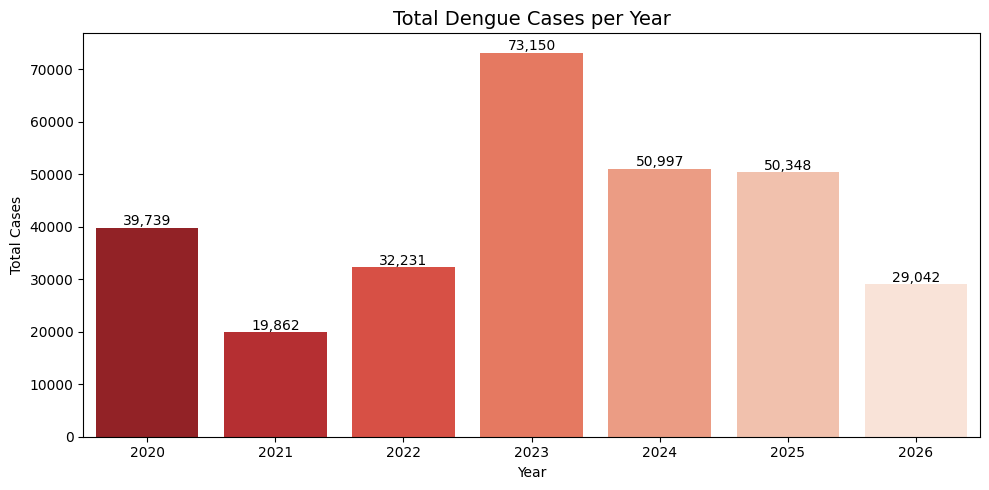

In [21]:
annual_cases = dengue_df.groupby('year')['cases'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x='year', y='cases', data=annual_cases, palette='Reds_r')
plt.title('Total Dengue Cases per Year', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Total Cases')
for i, row in annual_cases.iterrows():
    plt.text(i, row['cases'] + 500, f'{int(row["cases"]):,}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

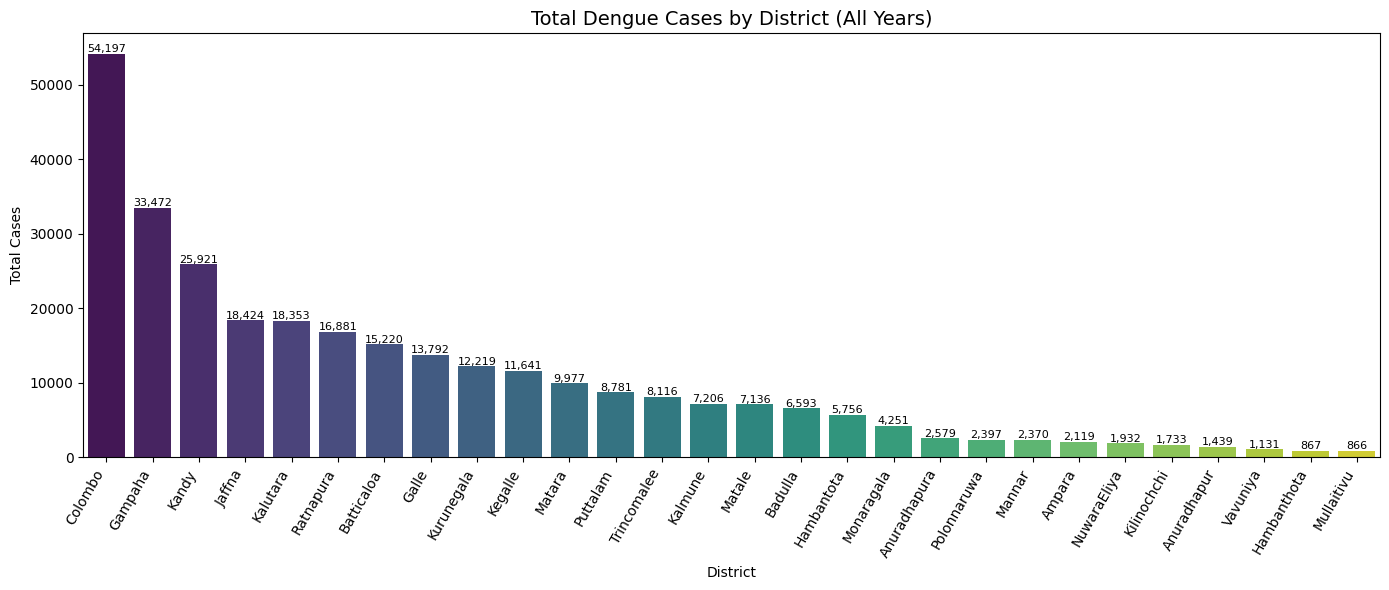

In [22]:
district_total = dengue_df.groupby('district')['cases'].sum().reset_index().sort_values(by='cases', ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x='district', y='cases', data=district_total, palette='viridis',hue='district', legend=False)
plt.title('Total Dengue Cases by District (All Years)', fontsize=14)
plt.xlabel('District')
plt.ylabel('Total Cases')
plt.xticks(rotation=60, ha='right')
for i, row in district_total.iterrows():
    plt.text(district_total.index.get_loc(i), row['cases'] + 200, f'{int(row["cases"]):,}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

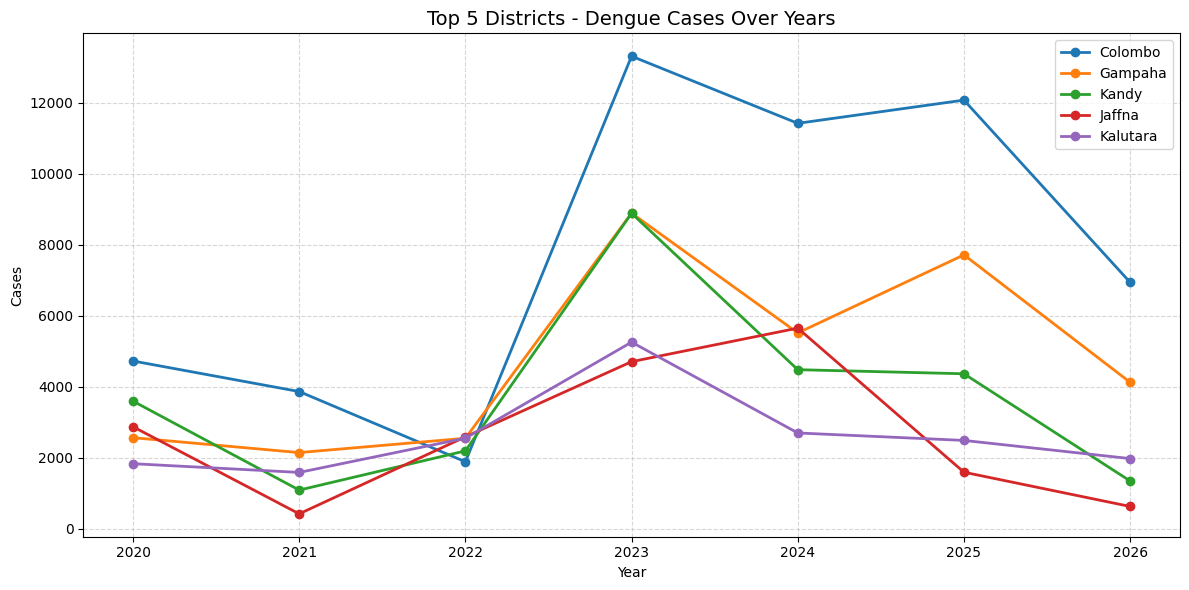

In [23]:
top_5_districts = district_total.head(5)['district'].tolist()
top5_df = dengue_df[dengue_df['district'].isin(top_5_districts)]
yearly_top5 = top5_df.groupby(['year', 'district'])['cases'].sum().reset_index()

plt.figure(figsize=(12, 6))
for district in top_5_districts:
    subset = yearly_top5[yearly_top5['district'] == district]
    plt.plot(subset['year'], subset['cases'], marker='o', linewidth=2, label=district)
plt.title('Top 5 Districts - Dengue Cases Over Years', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Cases')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

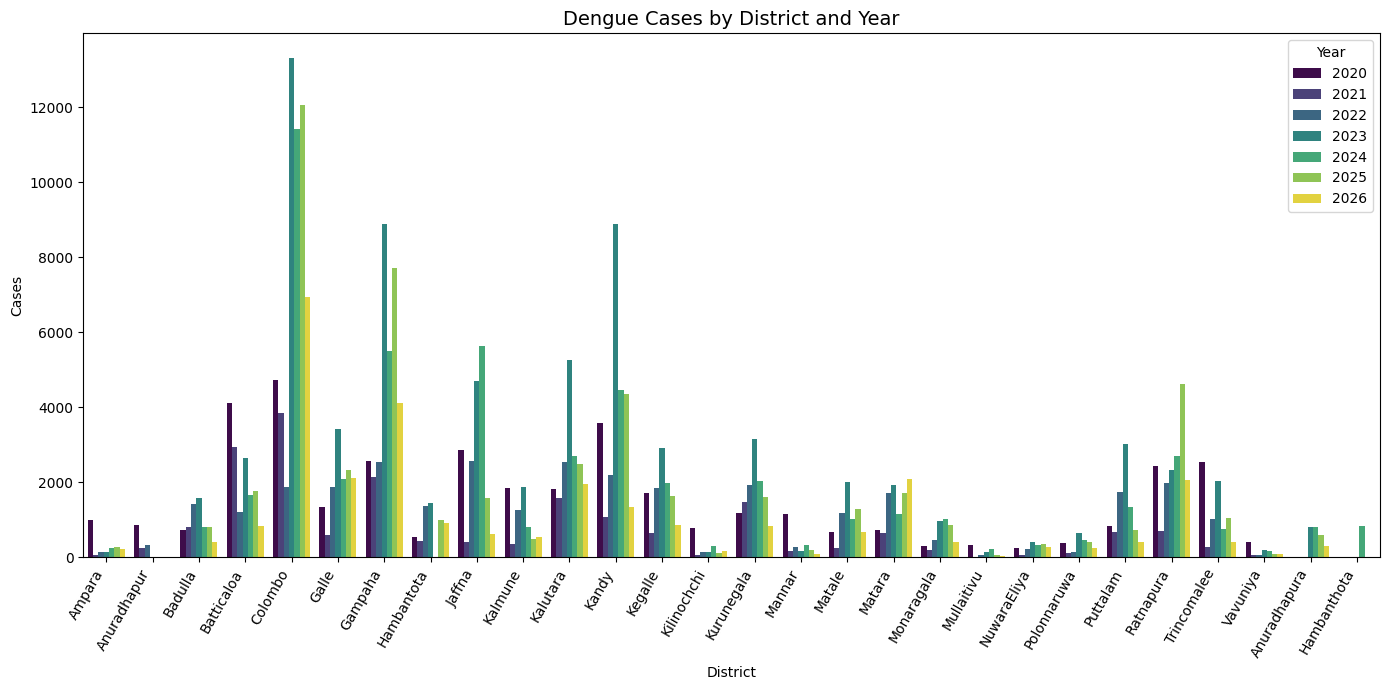

In [24]:
yearly_district = dengue_df.groupby(['year', 'district'])['cases'].sum().reset_index()

plt.figure(figsize=(14, 7))
sns.barplot(x='district', y='cases', hue='year', data=yearly_district, palette='viridis')  # Using a different palette for better visibility
plt.title('Dengue Cases by District and Year', fontsize=14)
plt.xlabel('District')
plt.ylabel('Cases')
plt.xticks(rotation=60, ha='right')
plt.legend(title='Year')
plt.tight_layout()
plt.show()

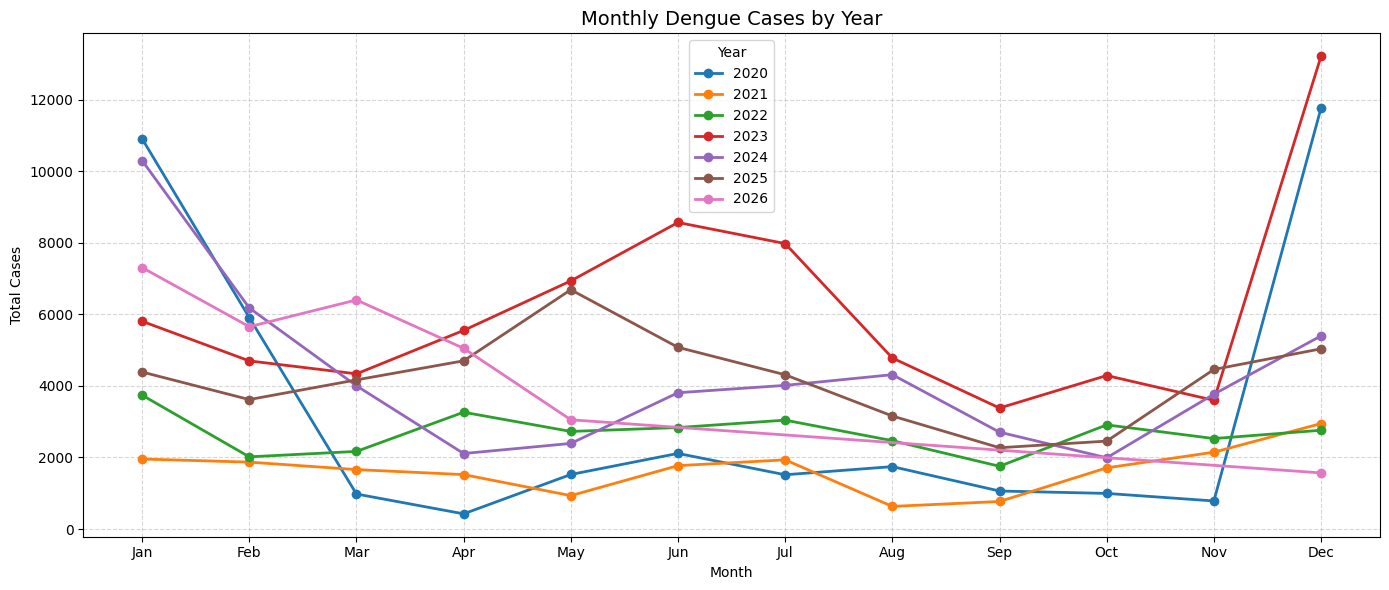

In [25]:
dengue_df['start.date'] = pd.to_datetime(dengue_df['start.date'])
dengue_df['month'] = dengue_df['start.date'].dt.month

monthly_cases = dengue_df.groupby(['year', 'month'])['cases'].sum().reset_index()

plt.figure(figsize=(14, 6))
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
for year in sorted(monthly_cases['year'].unique()):
    subset = monthly_cases[monthly_cases['year'] == year]
    plt.plot(subset['month'], subset['cases'], marker='o', linewidth=2, label=str(year))

plt.title('Monthly Dengue Cases by Year', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Total Cases')
plt.xticks(range(1, 13), months)
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

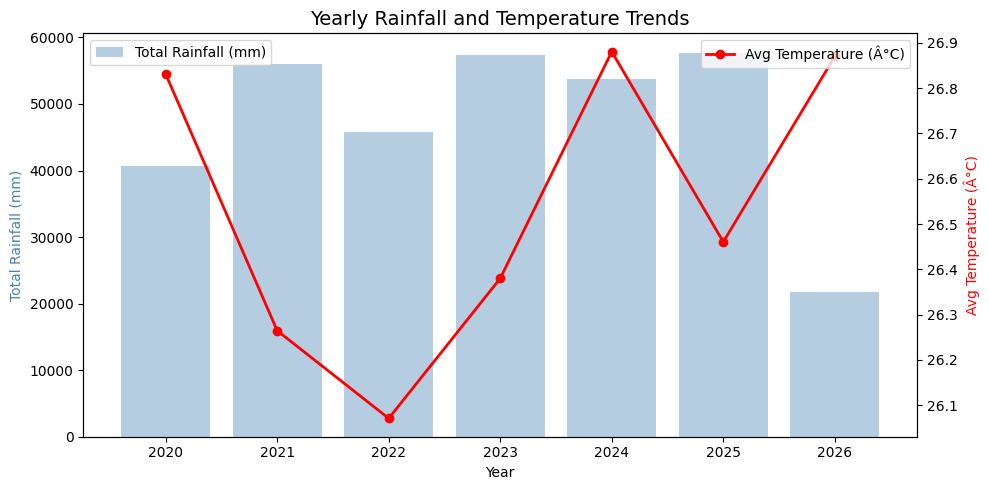

In [26]:
yearly_weather = weekly_weather.groupby('year').agg(
    avg_temp=('mean_temperature', 'mean'),
    total_rainfall=('weekly_rainfall', 'sum')
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.bar(yearly_weather['year'], yearly_weather['total_rainfall'], alpha=0.4, color='steelblue', label='Total Rainfall (mm)')
ax2.plot(yearly_weather['year'], yearly_weather['avg_temp'], color='red', marker='o', linewidth=2, label='Avg Temperature (Â°C)')

ax1.set_xlabel('Year')
ax1.set_ylabel('Total Rainfall (mm)', color='steelblue')
ax2.set_ylabel('Avg Temperature (Â°C)', color='red')
plt.title('Yearly Rainfall and Temperature Trends', fontsize=14)
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()

C:\Users\theek\AppData\Local\Temp\ipykernel_41024\3808845544.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='avg_rainfall', y='district', data=district_weather, palette='viridis', ax=axes[0])
C:\Users\theek\AppData\Local\Temp\ipykernel_41024\3808845544.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='avg_temp', y='district', data=district_weather_sorted_temp, palette='magma', ax=axes[1])


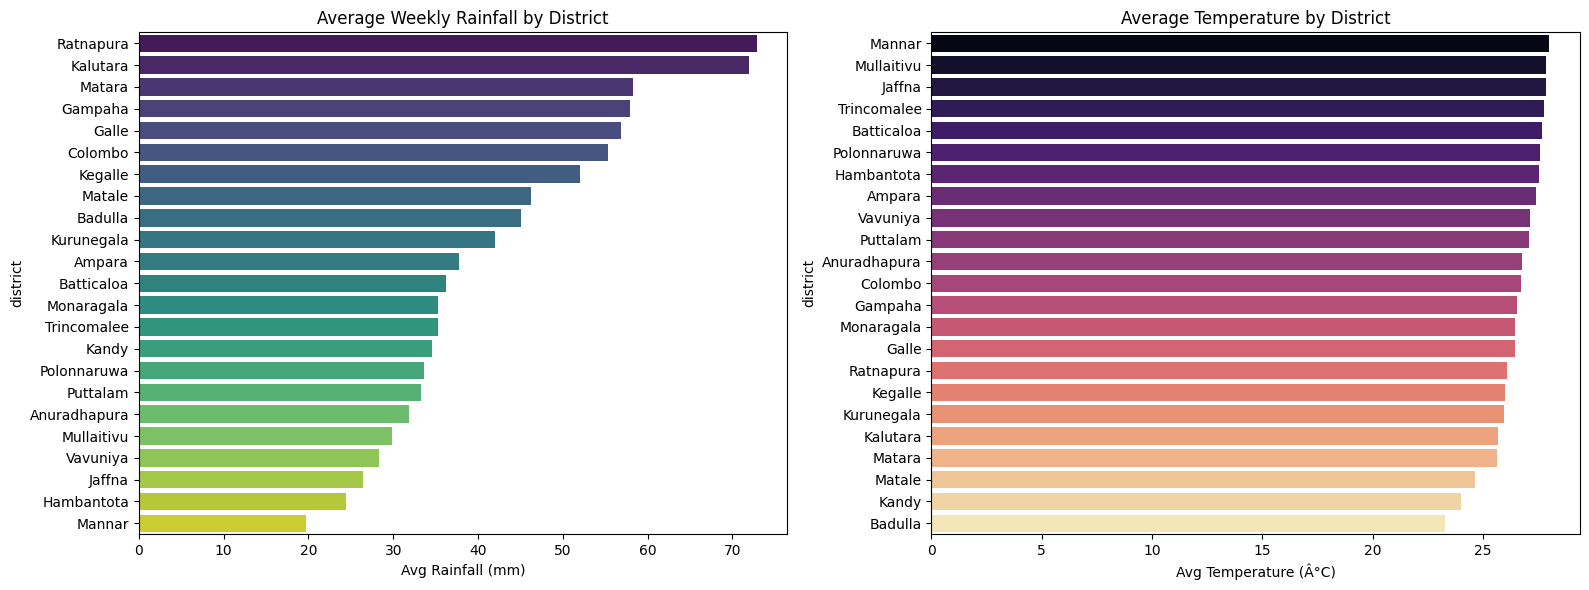

In [27]:
district_weather = weekly_weather.groupby('district').agg(
    avg_temp=('mean_temperature', 'mean'),
    avg_rainfall=('weekly_rainfall', 'mean')
).reset_index().sort_values(by='avg_rainfall', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x='avg_rainfall', y='district', data=district_weather, palette='viridis', ax=axes[0])
axes[0].set_title('Average Weekly Rainfall by District')
axes[0].set_xlabel('Avg Rainfall (mm)')

district_weather_sorted_temp = district_weather.sort_values(by='avg_temp', ascending=False)
sns.barplot(x='avg_temp', y='district', data=district_weather_sorted_temp, palette='magma', ax=axes[1])
axes[1].set_title('Average Temperature by District')
axes[1].set_xlabel('Avg Temperature (Â°C)')

plt.tight_layout()
plt.show()

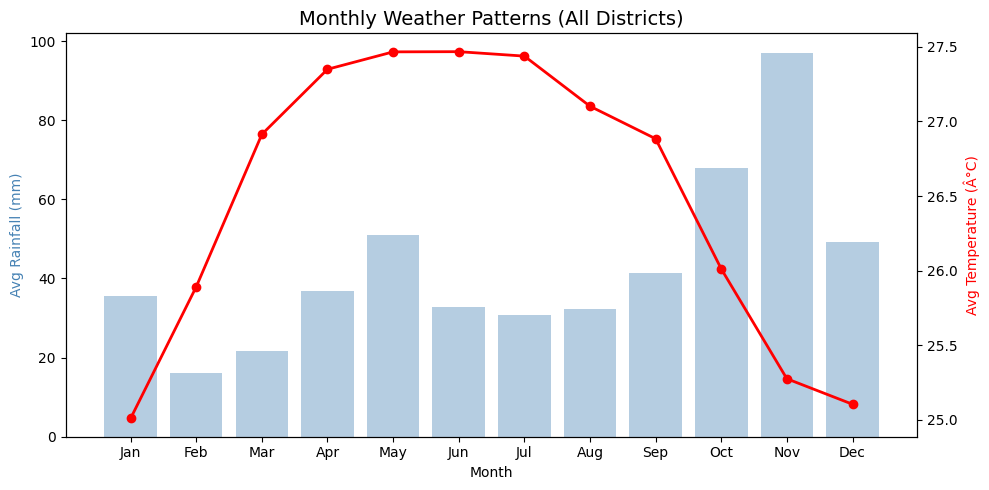

In [28]:
weekly_weather['month'] = pd.to_datetime(weekly_weather['week_start']).dt.month
monthly_weather = weekly_weather.groupby('month').agg(
    avg_temp=('mean_temperature', 'mean'),
    avg_rainfall=('weekly_rainfall', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ax1.bar(monthly_weather['month'], monthly_weather['avg_rainfall'], alpha=0.4, color='steelblue')
ax2.plot(monthly_weather['month'], monthly_weather['avg_temp'], color='red', marker='o', linewidth=2)

ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(months)
ax1.set_xlabel('Month')
ax1.set_ylabel('Avg Rainfall (mm)', color='steelblue')
ax2.set_ylabel('Avg Temperature (Â°C)', color='red')
plt.title('Monthly Weather Patterns (All Districts)', fontsize=14)
plt.tight_layout()
plt.show()

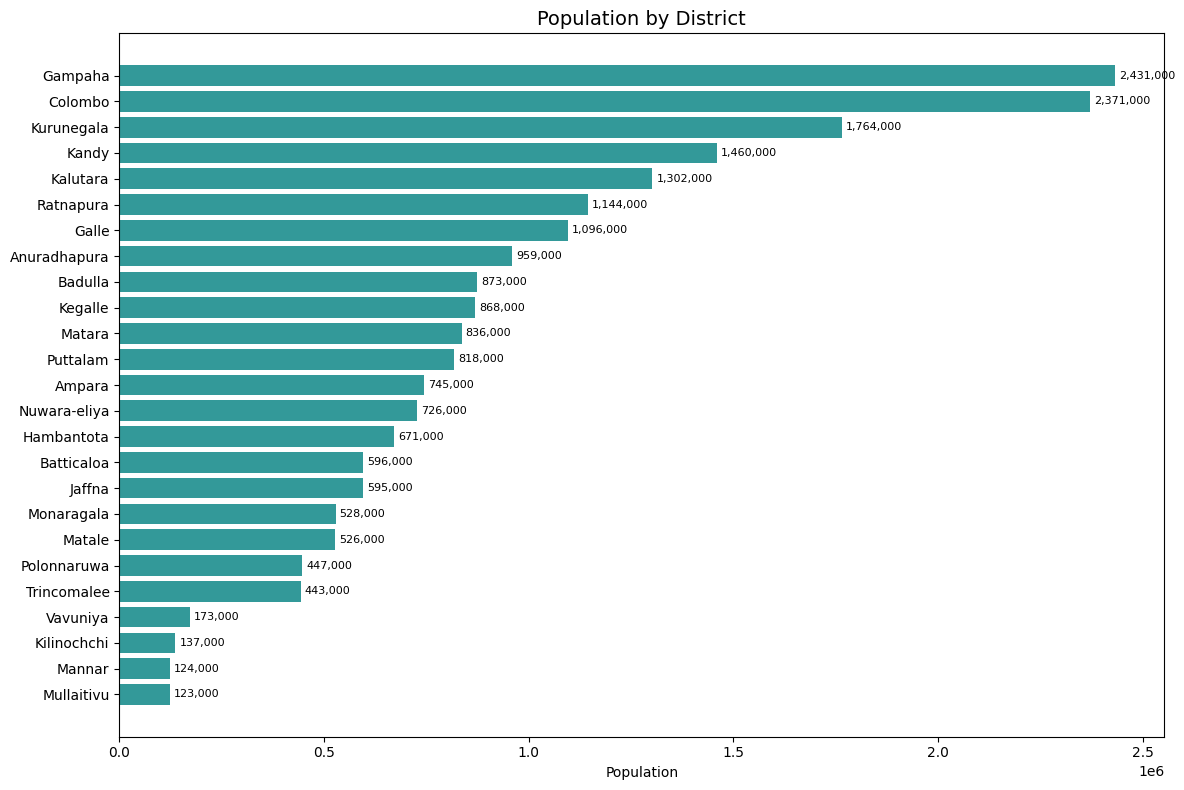

In [29]:
pop_sorted = population_df.sort_values(by='Population Count', ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
barh = ax.barh(pop_sorted['District'], pop_sorted['Population Count'], color='teal', alpha=0.8)
ax.set_title('Population by District', fontsize=14)
ax.set_xlabel('Population')
for bar in barh:
    width = bar.get_width()
    ax.text(width + 10000, bar.get_y() + bar.get_height()/2, f'{int(width):,}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

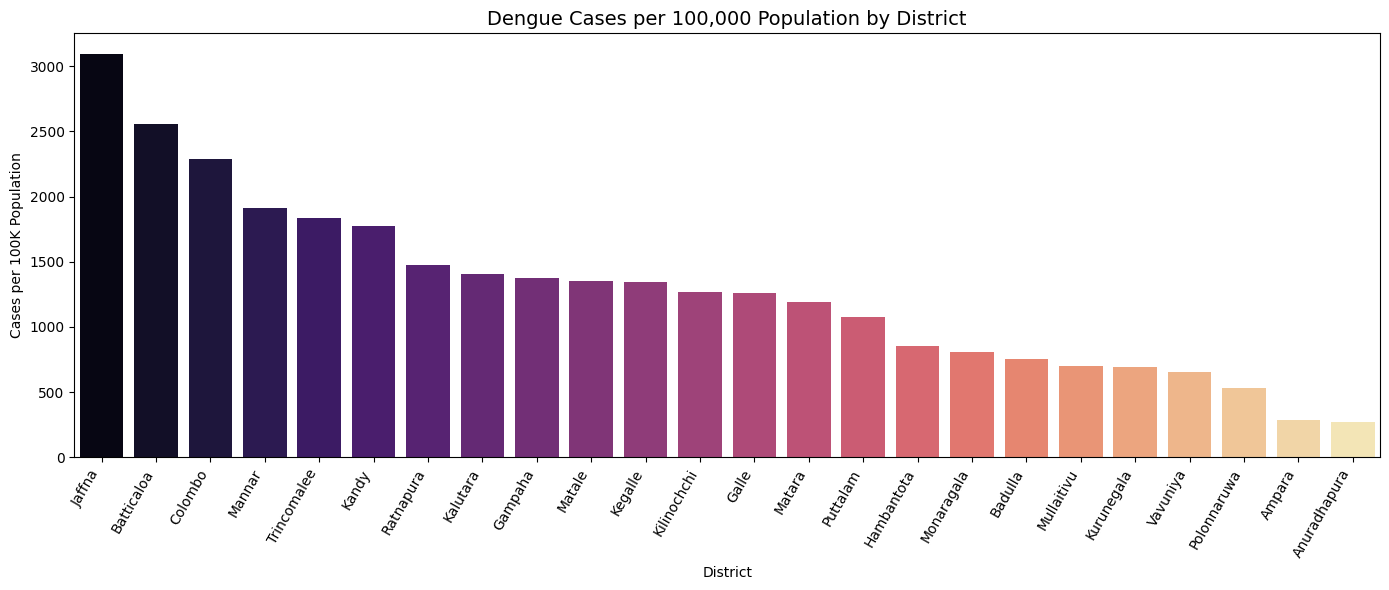

In [30]:
merged_df = dengue_df.merge(population_df, left_on='district', right_on='District', how='left')
merged_df = merged_df[merged_df['Population Count'].notna()]
merged_df['cases_per_100k'] = (merged_df['cases'] / merged_df['Population Count'] * 100000).round(2)

district_rate = merged_df.groupby('district')['cases_per_100k'].sum().reset_index().sort_values(by='cases_per_100k', ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x='district', y='cases_per_100k', data=district_rate, palette='magma',hue='district', legend=False)
plt.title('Dengue Cases per 100,000 Population by District', fontsize=14)
plt.xlabel('District')
plt.ylabel('Cases per 100K Population')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

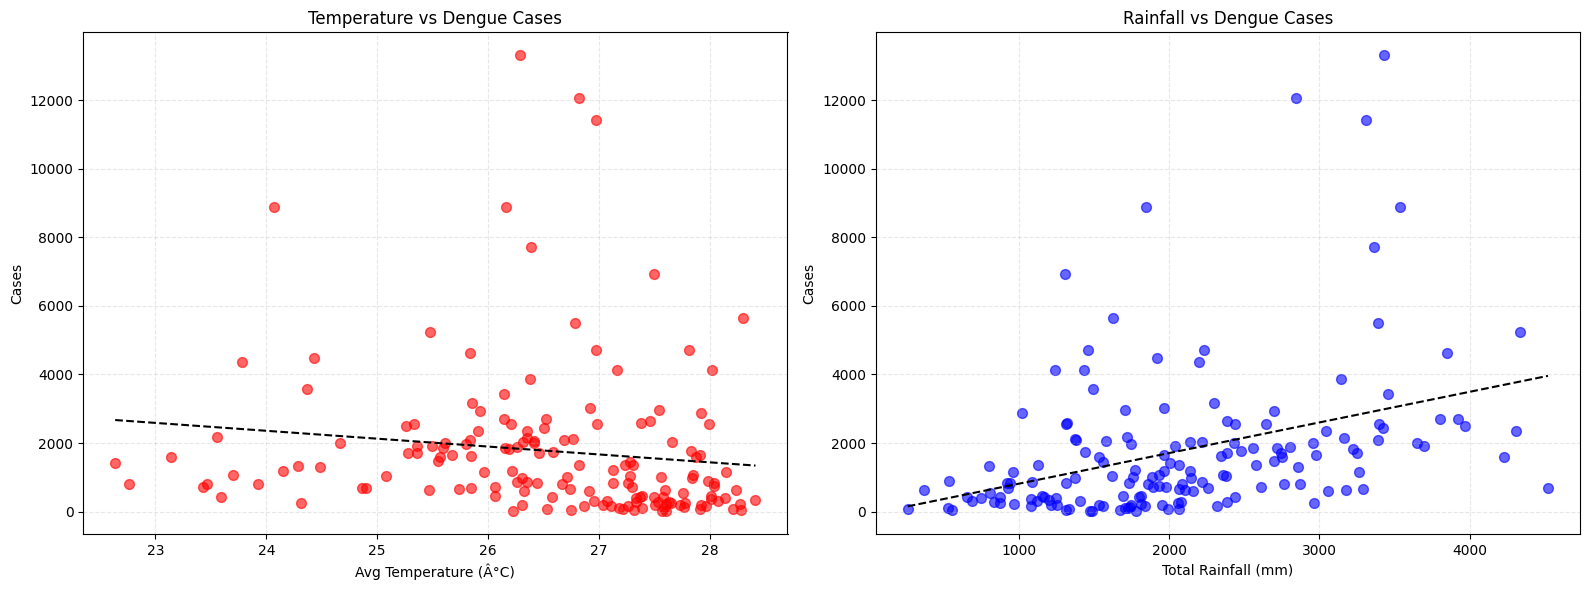

In [31]:
weather_merged = dengue_df.groupby(['district', 'year'])['cases'].sum().reset_index()
weather_merged = weather_merged.merge(
    weekly_weather.groupby(['district', 'year']).agg(
        avg_temp=('mean_temperature', 'mean'),
        total_rain=('weekly_rainfall', 'sum')
    ).reset_index(),
    on=['district', 'year'], how='left'
)
weather_merged = weather_merged.dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(weather_merged['avg_temp'], weather_merged['cases'], alpha=0.6, s=50, c='red')
z = np.polyfit(weather_merged['avg_temp'], weather_merged['cases'], 1)
p = np.poly1d(z)
axes[0].plot(sorted(weather_merged['avg_temp']), p(sorted(weather_merged['avg_temp'])), "--", color='black')
axes[0].set_title('Temperature vs Dengue Cases')
axes[0].set_xlabel('Avg Temperature (Â°C)')
axes[0].set_ylabel('Cases')
axes[0].grid(True, linestyle='--', alpha=0.3)

axes[1].scatter(weather_merged['total_rain'], weather_merged['cases'], alpha=0.6, s=50, c='blue')
z2 = np.polyfit(weather_merged['total_rain'], weather_merged['cases'], 1)
p2 = np.poly1d(z2)
axes[1].plot(sorted(weather_merged['total_rain']), p2(sorted(weather_merged['total_rain'])), "--", color='black')
axes[1].set_title('Rainfall vs Dengue Cases')
axes[1].set_xlabel('Total Rainfall (mm)')
axes[1].set_ylabel('Cases')
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

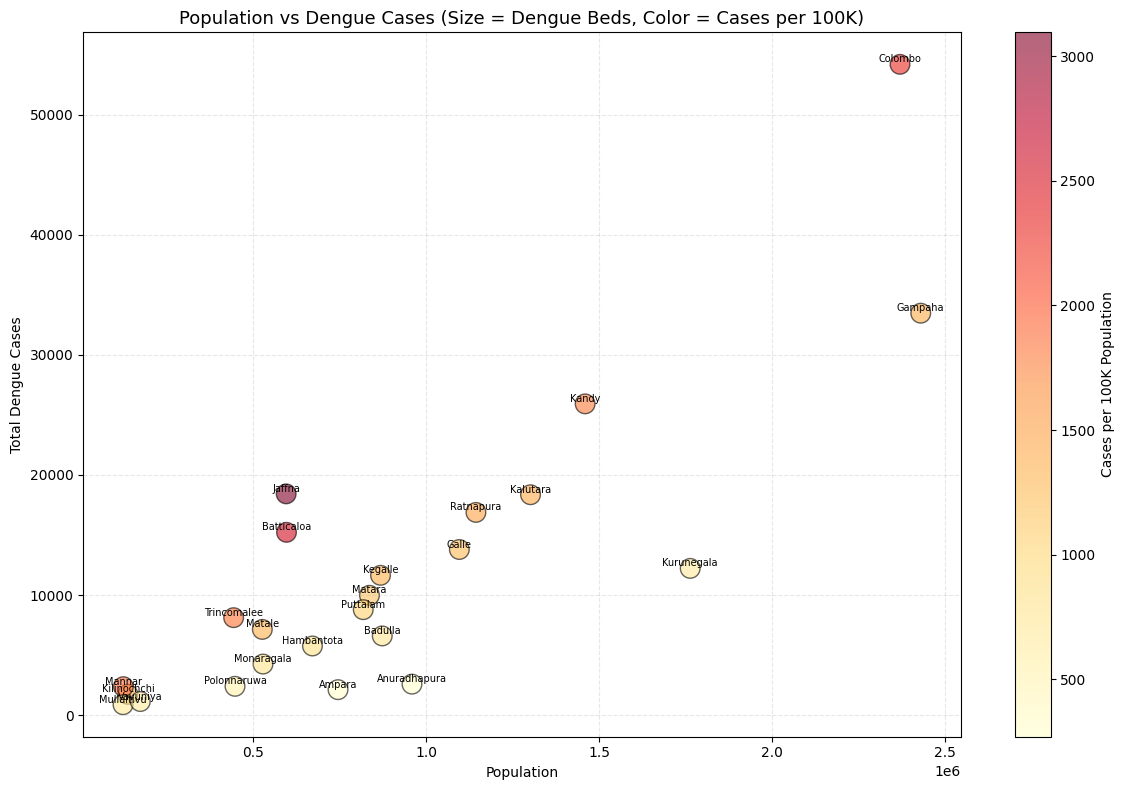

In [32]:
final_merged = dengue_df.groupby('district')['cases'].sum().reset_index()
final_merged = final_merged.merge(population_df[['District', 'Population Count']], left_on='district', right_on='District', how='left')
final_merged = final_merged.merge(bedsByDistricts[['District', 'beds for dengue']], left_on='district', right_on='District', how='left')
final_merged = final_merged.dropna()
final_merged['cases_per_100k'] = (final_merged['cases'] / final_merged['Population Count'] * 100000).round(1)

fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(final_merged['Population Count'], final_merged['cases'],
                      s=200, alpha=0.6,
                     c=final_merged['cases_per_100k'], cmap='YlOrRd', edgecolors='black')

for _, row in final_merged.iterrows():
    ax.annotate(row['district'], (row['Population Count'], row['cases']),
                fontsize=7, ha='center', va='bottom')

plt.colorbar(scatter, label='Cases per 100K Population')
ax.set_title('Population vs Dengue Cases (Size = Dengue Beds, Color = Cases per 100K)', fontsize=13)
ax.set_xlabel('Population')
ax.set_ylabel('Total Dengue Cases')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Dengue Cases Prediction & Bed Capacity Forecasting

## 1. Data Preparation & Feature Engineering

In [33]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded successfully!')

Libraries loaded successfully!


In [34]:
model_df = dengue_df[['year', 'week', 'district', 'cases']].copy()
model_df.rename(columns={'week': 'week_of_year'}, inplace=True)

model_df = model_df.merge(
    weekly_weather[['district', 'year', 'yearly_week_num', 'mean_temperature', 'weekly_rainfall']],
    left_on=['district', 'year', 'week_of_year'],
    right_on=['district', 'year', 'yearly_week_num'],
    how='left'
)

model_df = model_df.merge(
    population_df[['District', 'Population Count']],
    left_on='district', right_on='District', how='left'
)
model_df.drop(columns=['District', 'yearly_week_num'], inplace=True)

model_df.dropna(inplace=True)
print(f'Dataset shape: {model_df.shape}')
model_df.head(10)

Dataset shape: (7451, 7)


,year,week_of_year,district,cases,mean_temperature,weekly_rainfall,Population Count
0,2020,1,Colombo,535.0,26.33,4.6,2371000.0
1,2020,1,Gampaha,362.0,26.53,8.9,2431000.0
2,2020,1,Kalutara,168.0,26.07,12.7,1302000.0
3,2020,1,Kandy,199.0,23.84,0.5,1460000.0
4,2020,1,Matale,101.0,24.50,2.3,526000.0
6,2020,1,Galle,102.0,26.26,11.5,1096000.0
7,2020,1,Hambantota,45.0,26.56,14.8,671000.0
8,2020,1,Matara,49.0,25.69,14.0,836000.0
9,2020,1,Jaffna,378.0,26.01,5.5,595000.0
11,2020,1,Mannar,36.0,26.74,7.7,124000.0


In [35]:
model_df = model_df.sort_values(
    ['district', 'year', 'week_of_year']
).reset_index(drop=True)

# CREATE LAG FEATURES
model_df['cases_lag_1'] = (
    model_df.groupby('district')['cases']
    .shift(1)
)
model_df['cases_lag_2'] = (
    model_df.groupby('district')['cases']
    .shift(2)
)
model_df['cases_lag_4'] = (
    model_df.groupby('district')['cases']
    .shift(4)
)

# CREATE ROLLING FEATURES
model_df['cases_rolling_4'] = (
    model_df.groupby('district')['cases']
    .transform(
        lambda x: x.shift(1).rolling(window=4).mean()
    )
)
model_df['cases_rolling_8'] = (
    model_df.groupby('district')['cases']
    .transform(
        lambda x: x.shift(1).rolling(window=8).mean()
    )
)

model_df = model_df.dropna(
    subset=[
        'cases_lag_1',
        'cases_lag_2',
        'cases_lag_4',
        'cases_rolling_4',
        'cases_rolling_8'
    ]
).reset_index(drop=True)

features = [
    'year',
    'week_of_year',
    'district',
    'Population Count',
    'mean_temperature',
    'weekly_rainfall',
    'cases_lag_1',
    'cases_lag_2',
    'cases_lag_4',
    'cases_rolling_4',
    'cases_rolling_8'
]
target = 'cases'

model_df = model_df.sort_values(
    ['year', 'week_of_year', 'district']
).reset_index(drop=True)

X = model_df[features].copy()
y = model_df[target].copy()

split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print('========================================')
print('DATA SPLIT')
print('========================================')
print(f'Total samples    : {len(X)}')
print(f'Training samples : {len(X_train)}')
print(f'Testing samples  : {len(X_test)}')

DATA SPLIT
Total samples    : 7267
Training samples : 5813
Testing samples  : 1454


In [36]:
categorical_features = [
    'district',
]

numeric_features = [
    'year',
    'week_of_year',
    'Population Count',
    'mean_temperature',
    'weekly_rainfall',
    'cases_lag_1',
    'cases_lag_2',
    'cases_lag_4',
    'cases_rolling_4',
    'cases_rolling_8'
]


preprocessor = ColumnTransformer(
    transformers=[
        (
            'district',
            OneHotEncoder(
                handle_unknown='ignore', 
                sparse_output=False,
                drop='first'  
            ),
            categorical_features
        ),
        (
            'numeric',
            StandardScaler(),
            numeric_features
        )
    ]
)

print('Preprocessing pipeline defined!')

Preprocessing pipeline defined!


## Model Training & Evaluation

In [37]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.01, max_iter=10000),
    'Random Forest': RandomForestRegressor(
        n_estimators=300, max_depth=15,
        min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=300, max_depth=15,
        min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300, max_depth=5,
        learning_rate=0.05, random_state=42
    ),
    'XGBoost': XGBRegressor(
        n_estimators=500, max_depth=6,
        learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective='reg:squarederror',
        random_state=42, n_jobs=-1
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=500, learning_rate=0.05,
        num_leaves=31, max_depth=-1, subsample=0.8,
        colsample_bytree=0.8, random_state=42, verbosity=-1
    )
}


results = []
trained_models = {}

for name, model in models.items():
    print(f'\nTraining {name}...')
    
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })
    trained_models[name] = pipeline
    
    print(f'  MAE  : {mae:.4f}')
    print(f'  RMSE : {rmse:.4f}')
    print(f'  R2   : {r2:.4f}')


Training Linear Regression...
  MAE  : 12.7665
  RMSE : 23.4130
  R2   : 0.8856

Training Ridge Regression...
  MAE  : 12.7649
  RMSE : 23.4139
  R2   : 0.8856

Training Lasso Regression...
  MAE  : 12.7499
  RMSE : 23.4141
  R2   : 0.8856

Training Random Forest...
  MAE  : 11.3063
  RMSE : 22.5382
  R2   : 0.8940

Training Extra Trees...
  MAE  : 11.4022
  RMSE : 22.6965
  R2   : 0.8925

Training Gradient Boosting...
  MAE  : 11.6879
  RMSE : 23.8022
  R2   : 0.8818

Training XGBoost...
  MAE  : 11.5672
  RMSE : 22.8036
  R2   : 0.8915

Training LightGBM...
  MAE  : 12.7309
  RMSE : 24.9351
  R2   : 0.8703


In [38]:
# ============================================================
# 11. MODEL COMPARISON
# ============================================================
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('RMSE').reset_index(drop=True)

print('========================================')
print('MODEL COMPARISON')
print('========================================')
print(results_df.to_string(index=False))

MODEL COMPARISON
            Model       MAE      RMSE       R2
    Random Forest 11.306296 22.538171 0.894012
      Extra Trees 11.402248 22.696527 0.892518
          XGBoost 11.567219 22.803610 0.891501
Linear Regression 12.766508 23.412950 0.885625
 Ridge Regression 12.764852 23.413900 0.885616
 Lasso Regression 12.749906 23.414143 0.885613
Gradient Boosting 11.687941 23.802206 0.881790
         LightGBM 12.730943 24.935147 0.870269


In [39]:
best_model_name = results_df.iloc[0]['Model']
best_rmse = results_df.iloc[0]['RMSE']
best_mae = results_df.iloc[0]['MAE']
best_r2 = results_df.iloc[0]['R2']

print('========================================')
print('BEST MODEL')
print('========================================')
print(f'Model : {best_model_name}')
print(f'RMSE  : {best_rmse:.4f}')
print(f'MAE   : {best_mae:.4f}')
print(f'R2    : {best_r2:.4f}')

BEST MODEL
Model : Random Forest
RMSE  : 22.5382
MAE   : 11.3063
R2    : 0.8940


In [54]:
import joblib
# Save the best model pipeline
joblib.dump(trained_models['Random Forest'], 'best_model.pkl')
print("Model successfully saved as 'best_model.pkl'")

Model successfully saved as 'best_model.pkl'


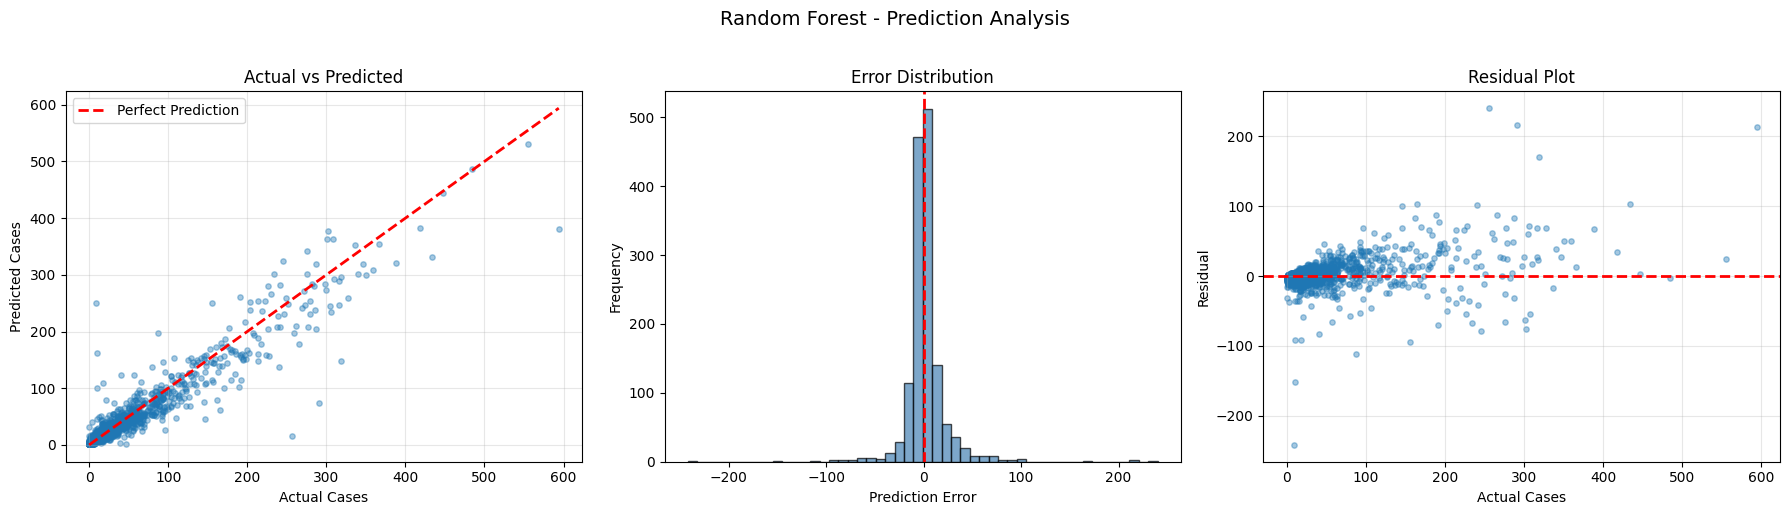

In [40]:
best_pipeline = trained_models[best_model_name]
y_pred_best = best_pipeline.predict(X_test)

comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred_best})
comparison['Error'] = comparison['Actual'] - comparison['Predicted']
comparison['Abs_Error'] = comparison['Error'].abs()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(comparison['Actual'], comparison['Predicted'], alpha=0.4, s=15)
max_val = max(comparison['Actual'].max(), comparison['Predicted'].max())
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Cases')
axes[0].set_ylabel('Predicted Cases')
axes[0].set_title('Actual vs Predicted')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(comparison['Error'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Prediction Error')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Error Distribution')

axes[2].scatter(comparison['Actual'], comparison['Error'], alpha=0.4, s=15)
axes[2].axhline(0, color='red', linestyle='--', linewidth=2)
axes[2].set_xlabel('Actual Cases')
axes[2].set_ylabel('Residual')
axes[2].set_title('Residual Plot')
axes[2].grid(True, alpha=0.3)

plt.suptitle(f'{best_model_name} - Prediction Analysis', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 3. Feature Importance

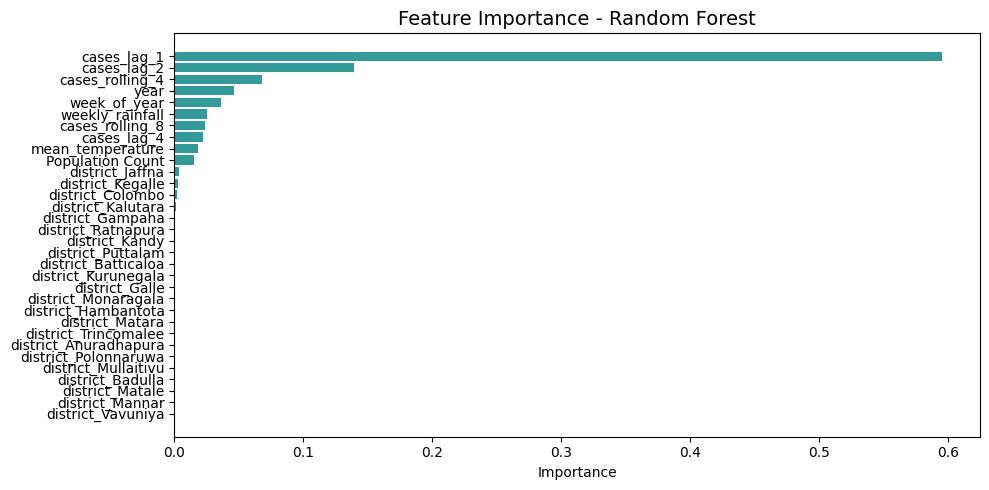

In [41]:
best_pipeline = trained_models[best_model_name]
best_est = best_pipeline.named_steps['model']

if hasattr(best_est, 'feature_importances_'):
    ohe_feature_names = list(
        best_pipeline.named_steps['preprocessor']
        .named_transformers_['district']
        .get_feature_names_out(categorical_features)
    )
    all_feature_names = ohe_feature_names + numeric_features
    
    importance_df = pd.DataFrame({
        'Feature': all_feature_names,
        'Importance': best_est.feature_importances_
    }).sort_values(by='Importance', ascending=True)
    
    plt.figure(figsize=(10, 5))
    plt.barh(importance_df['Feature'], importance_df['Importance'], color='teal', alpha=0.8)
    plt.title(f'Feature Importance - {best_model_name}', fontsize=14)
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()
elif hasattr(best_est, 'coef_'):
    ohe_feature_names = list(
        best_pipeline.named_steps['preprocessor']
        .named_transformers_['district']
        .get_feature_names_out(categorical_features)
    )
    all_feature_names = ohe_feature_names + numeric_features
    
    importance_df = pd.DataFrame({
        'Feature': all_feature_names,
        'Coefficient': np.abs(best_est.coef_)
    }).sort_values(by='Coefficient', ascending=True)
    
    plt.figure(figsize=(10, 5))
    plt.barh(importance_df['Feature'], importance_df['Coefficient'], color='teal', alpha=0.8)
    plt.title(f'Feature Coefficients (Absolute) - {best_model_name}', fontsize=14)
    plt.xlabel('|Coefficient|')
    plt.tight_layout()
    plt.show()

in Averagely dengue patient stay at hospital 7days.if we give the week cases. then we can consider it as the total capacity used in the week

Capacity_Utilization = (Predicted Weekly Cases / District Bed Capacity) × 100

In [ ]:
def predictOutbreak(district,cases):
    weekly_bed_capacity = bedsByDistricts[bedsByDistricts['District'] == district][['beds for dengue']].values[0][0]
    capacity_utilization = round(((cases / weekly_bed_capacity) * 100),2)
    if capacity_utilization < 70:
        return ["🟢 Normal", capacity_utilization]
    elif capacity_utilization < 85:
        return ["🟡 Warning", capacity_utilization]
    elif capacity_utilization < 100:
        return ["🟠 High Risk", capacity_utilization]
    else:
        return ["🔴 Capacity Outbreak", capacity_utilization]


['🟢 Normal', np.float64(31.61)]